<a href="https://colab.research.google.com/github/encen-ya/ML_2026/blob/main/pertemuan_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1

### Klasifikasi SVM dengan Data Dummy Linier


### Langkah 1 - Import Library



In [11]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 16.1 MB/s  0:00:00


In [2]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns

### Langkah 2 - Membuat Data Dummy

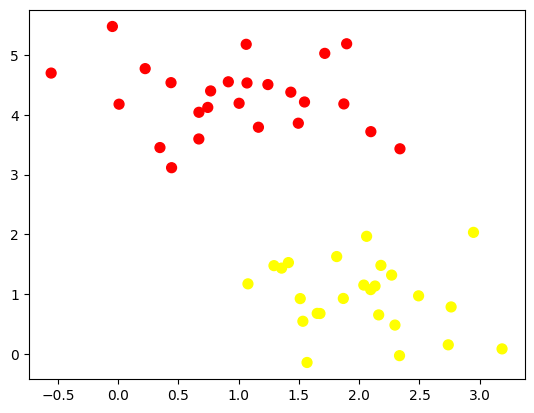

In [3]:
	from sklearn.datasets import make_blobs
	X, y = make_blobs(n_samples=50, centers=2,
	                  random_state=0, cluster_std=0.60)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

### Langkah 3 - Buat Ilustrasi Garis Pemisah

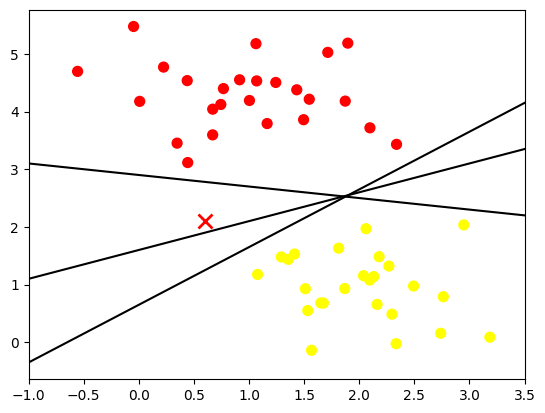

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

xfit = np.linspace(-1, 3.5)


for m, c in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + c, '-k')

plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)
plt.xlim(-1, 3.5)
plt.show()

### Langkah 4 - Ilustrasi Margin

(-1.0, 3.5)

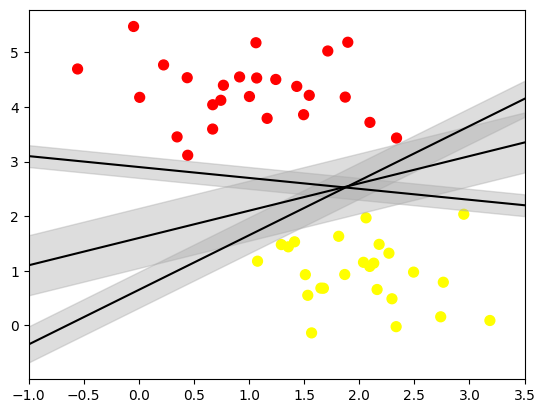

In [6]:
	xfit = np.linspace(-1, 3.5)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

	for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
	    yfit = m * xfit + b
	    plt.plot(xfit, yfit, '-k')
	    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
	                     color='#AAAAAA', alpha=0.4)

	plt.xlim(-1, 3.5)

### Langkah 5 - Fitting Model

In [7]:
	from sklearn.svm import SVC # "Support vector classifier"
	model = SVC(kernel='linear', C=1E10)
	model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

In [8]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

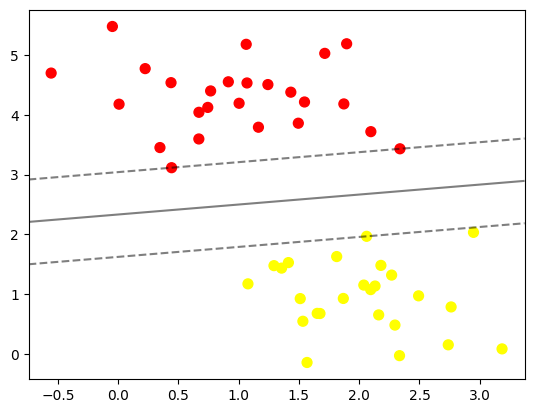

In [9]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(model)

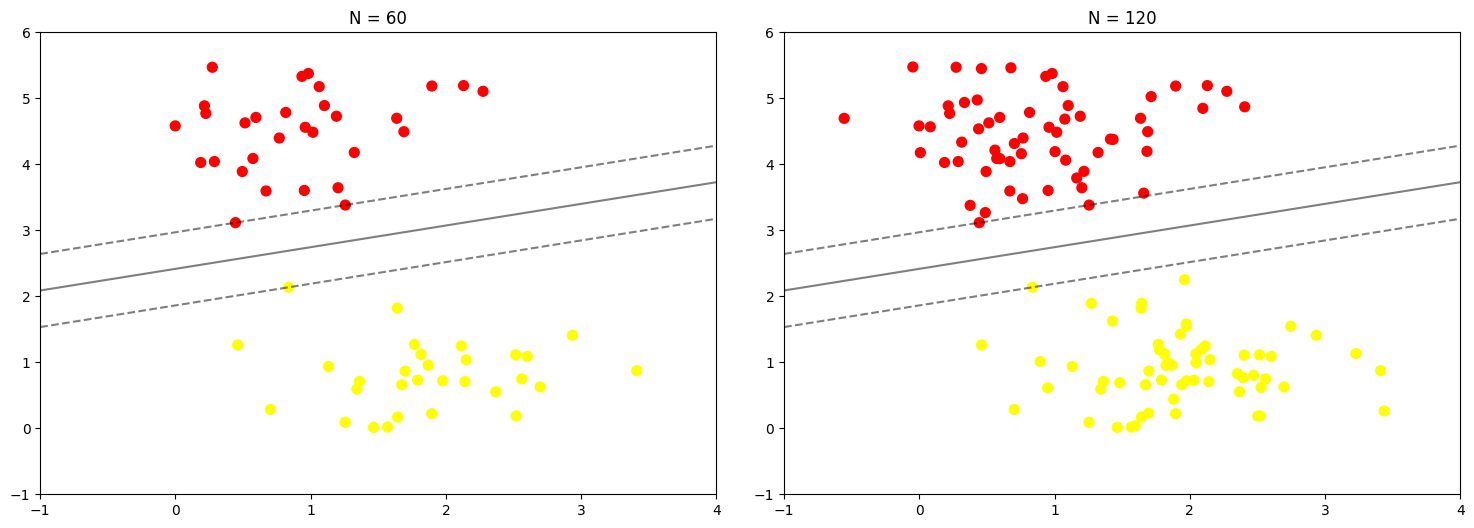

In [10]:
	def plot_svm(N=10, ax=None):
	    X, y = make_blobs(n_samples=200, centers=2,
	                      random_state=0, cluster_std=0.60)
	    X = X[:N]
	    y = y[:N]
	    model = SVC(kernel='linear', C=1E10)
	    model.fit(X, y)

	    ax = ax or plt.gca()
	    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    ax.set_xlim(-1, 4)
	    ax.set_ylim(-1, 6)
	    plot_svc_decision_function(model, ax)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
	for axi, N in zip(ax, [60, 120]):
	    plot_svm(N, axi)
	    axi.set_title('N = {0}'.format(N))

In [12]:
	# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

	from ipywidgets import interact, fixed
	interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

# Praktikum 2
### Klasifikasi SVM dengan Data Dummy Non-Linier



### Langkah 1 - Ilustrasi Data Non-Linier


Langkah 1a - Import Library

In [13]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

Langkah 1b - Buat Kembali Fungsi Plotting

In [14]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

Langkah 1c - Buat Data Dummy Non-Linier

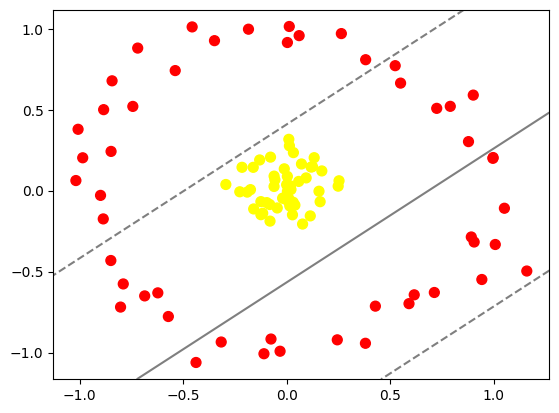

In [15]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

Karena proyeksi radial tidak cukup menggunakan model 2D, maka plot visualisasi diubah menjadi model 3D.

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-1.01776500e+00,  6.24520899e-02],
       [-1.61217961e-01,  1.44047064e-01],
       [ 2.41195034e-04,  3.67752183e-02],
       [-7.89014425e-01, -5.76257171e-01],
       [-1.58995704e-01, -1.12981610e-01],
       [ 1.16018927e+00, -4.96451799e-01],
       [ 6.16448602e-01, -6.43474220e-01],
       [-1.30156968e-01,  1.89645770e-01],
       [ 8.78538546e-01,  3.02950950e-01],
       [-1.12430806e-02,  1.34856892e-01],
       [ 7.90568295e-01,  5.20855371e-01],
       [-1.24226882e-01, -6.78271298e-02],
       [-5.38005597e-01,  7.41711491e-01],
       [ 9.44219637e-02,  7.87856161e-02],
       [-1.93015239e-02, -4.64555798e-02],
       [ 2.49072526e-01,  2.77495381e-02],
       [-8.47894555e-01,  2.42390726e-01],
       [ 9.43024615e-01, -5.48814519e-01],
       [-7.54438246e-02, -9.16594955e-01],
       [ 1.28984638e-02,  1.01415940e+00],
       [ 1.14301175e-01, -1.55974673e-01],
       [ 1.33174015e-01,  2.03658119e-01],
       [ 1.05200823e+00, -1.08683438e-01],
       [-3.15875595e-01, -9.35005086e-01],
       [ 5.24523638e-01,  7.72002691e-01],
       [ 3.81839209e-01,  8.08893545e-01],
       [-9.84833206e-01,  2.03000431e-01],
       [ 2.64450390e-01,  9.70256583e-01],
       [ 2.53218512e-01,  6.09809859e-02],
       [-4.37540632e-01, -1.06141130e+00],
       [ 9.01591226e-01,  5.90274604e-01],
       [ 1.83773517e-02,  2.98564676e-02],
       [ 1.54862924e-02, -9.43547763e-02],
       [-1.09409393e-01, -1.00746508e+00],
       [ 1.18604467e-01,  1.45540554e-01],
       [ 1.61911447e-01, -6.82023094e-02],
       [-6.06960141e-02,  2.59418604e-02],
       [ 3.77371858e-03,  9.15139899e-01],
       [-3.48340694e-01,  9.26574581e-01],
       [ 1.70122535e-01,  1.21846106e-01],
       [-7.77220132e-02,  2.07098725e-01],
       [-4.52243675e-02, -1.06920743e-01],
       [-3.15678449e-02, -9.91938083e-01],
       [-8.15076405e-02, -8.56333754e-02],
       [ 2.83445095e-02, -1.49162434e-01],
       [ 4.28771357e-01, -7.13448607e-01],
       [ 2.10452037e-02,  7.13719019e-03],
       [-7.42759980e-01,  5.20378600e-01],
       [ 3.80769492e-01, -9.42883751e-01],
       [ 9.05870754e-01, -3.17229090e-01],
       [-1.24110776e-01, -1.48527365e-01],
       [-1.15460690e-01, -1.39521743e-01],
       [ 1.56445979e-01, -3.56190768e-03],
       [-6.22036986e-01, -6.31357528e-01],
       [-1.00719771e+00,  3.79099442e-01],
       [ 4.00648489e-02, -8.93522967e-02],
       [-8.48967157e-01, -4.31528059e-01],
       [ 9.97572346e-01,  2.04571853e-01],
       [ 1.41980376e-02, -7.74087846e-02],
       [ 2.44805482e-01, -9.21487812e-01],
       [-2.93506077e-01,  3.80437162e-02],
       [ 7.13550352e-01, -6.29075462e-01],
       [-1.84138906e-01,  9.97349781e-01],
       [ 7.18739652e-02,  1.64902395e-01],
       [-8.85613477e-01, -1.74544693e-01],
       [-1.74569278e-01,  6.24373873e-03],
       [ 5.91208229e-01, -6.98013940e-01],
       [ 5.85143158e-02,  5.70594167e-02],
       [-3.59641078e-03, -5.41361276e-02],
       [-6.85467729e-01, -6.50181616e-01],
       [ 1.07242640e-02,  3.17101336e-01],
       [ 9.96430209e-01,  1.99662108e-01],
       [-2.15369735e-01,  1.44247527e-01],
       [ 5.50515273e-01,  6.64300139e-01],
       [ 1.00792205e+00, -3.32584975e-01],
       [-8.98755565e-01, -2.91900463e-02],
       [ 1.35429772e-02,  2.77173182e-01],
       [-7.19182863e-01,  8.80743474e-01],
       [ 9.56208103e-03,  1.93060585e-02],
       [ 6.05634584e-02,  9.57633323e-01],
       [-8.01431197e-02, -1.88133483e-01],
       [ 3.28318303e-02,  2.35001632e-01],
       [ 3.62522331e-03,  8.80548618e-02],
       [ 3.85067812e-03, -4.68046576e-03],
       [-4.56235166e-01,  1.01142259e+00],
       [ 1.03524576e-02, -4.85790268e-02],
       [-8.02022203e-01, -7.19173679e-01],
       [-5.71221341e-01, -7.77450365e-01],
       [-6.04487720e-02,  8.97477789e-02],
       [ 7.71708567e-02, -2.06239647e-01],
       [ 1.24916403e-01,  1.48920146e-01],
       [ 8.92110116e-01, -2.86137128e-01

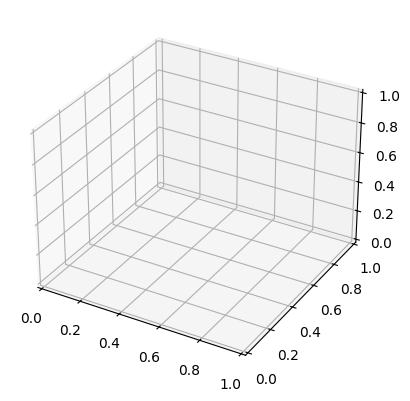

In [16]:
	from mpl_toolkits import mplot3d
	from ipywidgets import interact, fixed

	def plot_3D(elev=30, azim=30, X=X, y=y):
	    ax = plt.subplot(projection='3d')
	    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
	    ax.view_init(elev=elev, azim=azim)
	    ax.set_xlabel('x')
	    ax.set_ylabel('y')
	    ax.set_zlabel('r')

	interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
	         X=fixed(X), y=fixed(y))

### Langkah 2 - Fitting Model


In [17]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

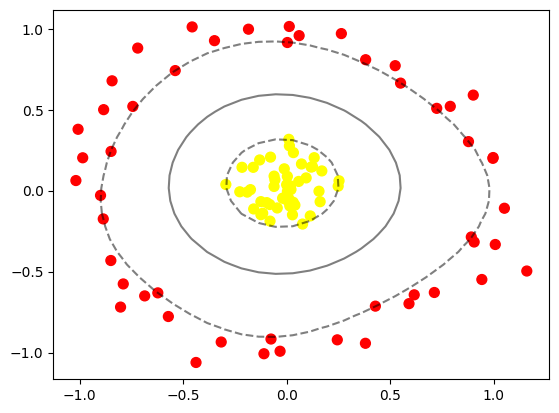

In [18]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')

# Praktikum 3
### SVM Data Overlapping

### Langkah 1 - Import Library dan Buat Fungsi Plotting



In [19]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC
	from sklearn.datasets import make_blobs

In [20]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

### Langkah 2 - Buat Data Dummy

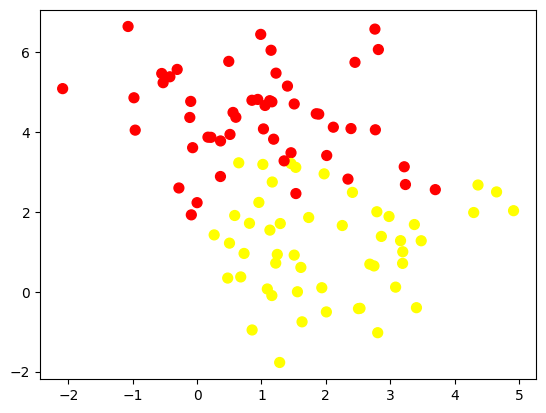

In [21]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=1.2)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

### Langkah 3 - Analisis Dampak Tunning

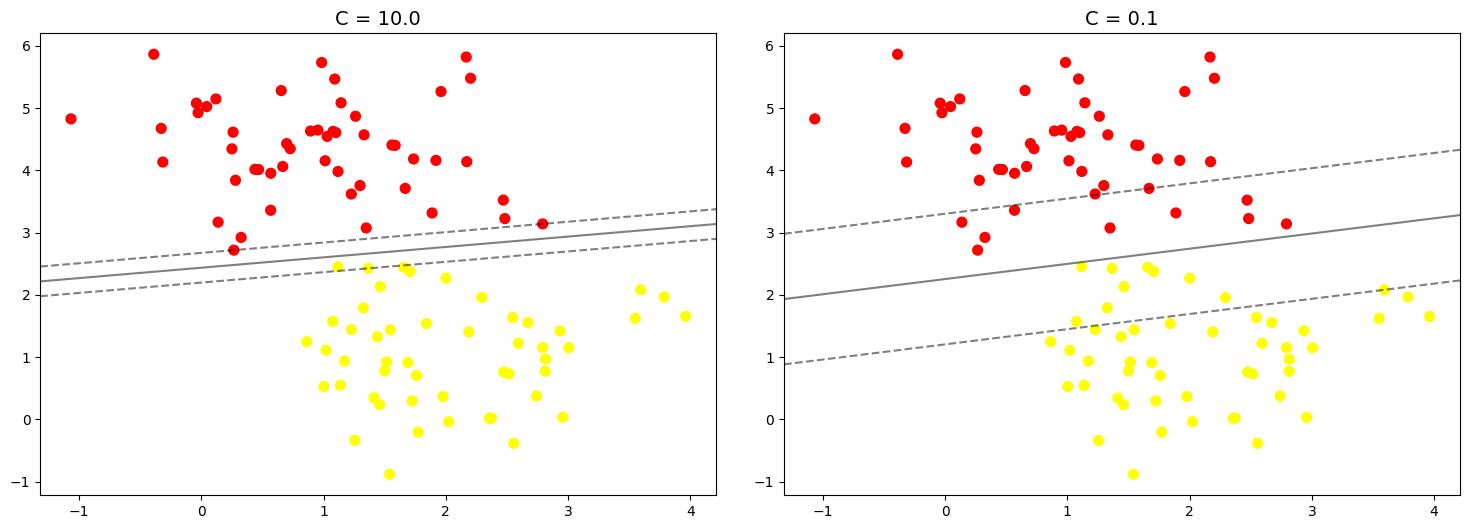

In [22]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=0.8)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

	for axi, C in zip(ax, [10.0, 0.1]):
	    model = SVC(kernel='linear', C=C).fit(X, y)
	    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    plot_svc_decision_function(model, axi)
	    axi.scatter(model.support_vectors_[:, 0],
	                model.support_vectors_[:, 1],
	                s=300, lw=1, facecolors='none');
	    axi.set_title('C = {0:.1f}'.format(C), size=14)

# Praktikum 4
### Klasifikasi Citra Wajah

### Langkah 0 - Unduh Dataset

In [23]:
	from sklearn.datasets import fetch_lfw_people
	faces = fetch_lfw_people(min_faces_per_person=60)
	print(faces.target_names)
	print(len(faces.target_names))
	print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


### Langkah 1 - Inspeksi Citra Wajah

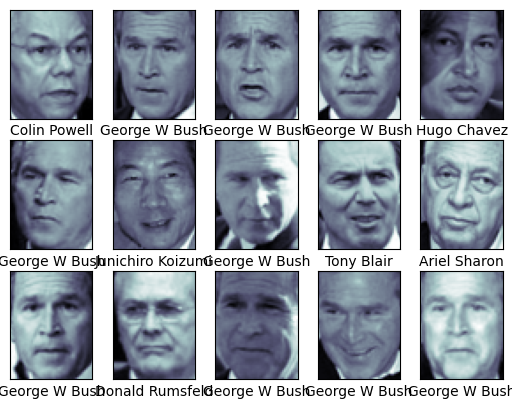

In [24]:
	# contoh wajah yang digunakan
	from matplotlib import pyplot as plt

	fig, ax = plt.subplots(3, 5)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(faces.images[i], cmap='bone')
	    axi.set(xticks=[], yticks=[],
	            xlabel=faces.target_names[faces.target[i]])

### Langkah 2 - Pra Pengolahan Data

In [25]:
	from sklearn.svm import SVC
	from sklearn.decomposition import PCA as RandomizedPCA
	from sklearn.pipeline import make_pipeline

	pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
	svc = SVC(kernel='rbf', class_weight='balanced')

	# Pipeline digunakan untuk melakukan proses secara bertahap dalam
	# 1 eksekusi fungsi secara langsung
	model = make_pipeline(pca, svc)

### Langkah 3 - Split Data

In [26]:
	# pemisahan data training dan data testing

	from sklearn.model_selection import train_test_split
	Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

### Langkah 4 - Pembuatan Model + Tunning

In [27]:
	from sklearn.model_selection import GridSearchCV
	param_grid = {'svc__C': [1, 5, 10, 50],
	              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
	grid = GridSearchCV(model, param_grid)

	%time grid.fit(Xtrain, ytrain)
	print(grid.best_params_)
	print(grid.best_score_)

CPU times: user 2min 16s, sys: 242 ms, total: 2min 17s
Wall time: 1min 51s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


Sehingga didapatkan informasi bahwa, hyperparameter terbaik dari model SVM yang kita buat adalah dengan, C=5 dan Gamma=0.001 dengan tingkat akurasi 82.88%.

Gunakan model terbaik tersebut untuk proses prediksi.

In [28]:
	model = grid.best_estimator_
	yfit = model.predict(Xtest)

### Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

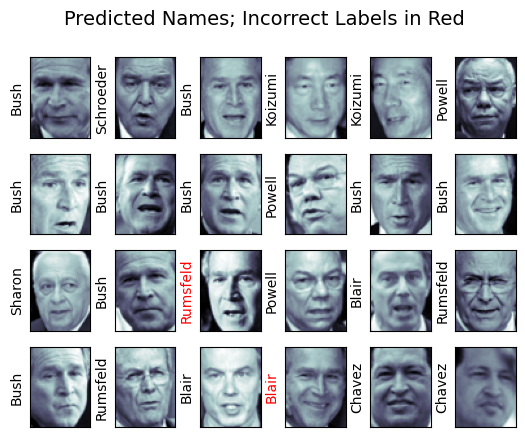

In [29]:
	# hasil label pada data testing

	fig, ax = plt.subplots(4, 6)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
	    axi.set(xticks=[], yticks=[])
	    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
	                   color='black' if yfit[i] == ytest[i] else 'red')
	fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

### Langkah 6 - Cek Performansi

In [30]:
	from sklearn.metrics import classification_report
	print(classification_report(ytest, yfit,
	                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Selanjutnya, kita dapat menggunakan confusion matrix untuk mengetahui label label yang terklasifikasi  dengan benar dan tidak.

Text(113.92222222222219, 0.5, 'predicted label')

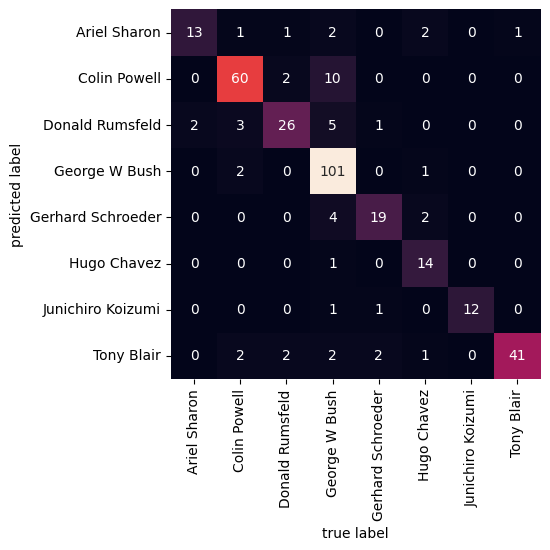

In [31]:
	# bentuk confusion matrix
	from sklearn.metrics import confusion_matrix
	import seaborn as sns

	mat = confusion_matrix(ytest, yfit)
	sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
	            xticklabels=faces.target_names,
	            yticklabels=faces.target_names)
	plt.xlabel('true label')
	plt.ylabel('predicted label')

# Praktikum 5
### Klasifikasi Citra Siang dan Malang



### Langkah 0 - Import Library



In [12]:
	# Import Required Libraries
	from pathlib import Path
	import matplotlib.image as mpimg
	import matplotlib.pyplot as plt
	import cv2
	import random
	import numpy as np
	import pandas as pd

In [13]:
from google.colab import files
uploaded = files.upload()

Saving images.zip to images.zip


In [9]:
	# Image directories
	train_dir = "images/training/"
	test_dir = "images/test/"

### Langkah 1 - Load Data dan Visualisasikan

In [10]:
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    dirs = p.glob('*')

	    img_list = []

	    for dir in dirs:
	        label = str(dir).split('/')[-1]
	        for file in dir.glob('*.jpg'):
	            img = mpimg.imread(file)

	            if not img is None:
	                img_list.append((img, label))

	    return img_list

Load training data


In [14]:
	# Load training data
	train_img = load_dataset(train_dir)

Lakukan pengecekan pada salah satu data pada list. List harus berisi tuple dengan dua data, yaitu data gambar dan label dari gambar.

In [15]:
	# Extract the uploaded zip file
	import zipfile
	with zipfile.ZipFile('images.zip', 'r') as zip_ref:
	    zip_ref.extractall('.')

	# Reload the training data after extraction
	train_img = load_dataset(train_dir)

	# Check the first data
	# It should be a tuple consist of arrays of image and image labels
	train_img[0]

(array([[[186, 199, 208],
         [160, 173, 182],
         [163, 176, 185],
         ...,
         [176, 189, 198],
         [176, 189, 198],
         [176, 189, 198]],
 
        [[186, 199, 208],
         [160, 173, 182],
         [163, 176, 185],
         ...,
         [176, 189, 198],
         [176, 189, 198],
         [176, 189, 198]],
 
        [[186, 199, 208],
         [160, 173, 182],
         [163, 176, 185],
         ...,
         [176, 189, 198],
         [176, 189, 198],
         [176, 189, 198]],
 
        ...,
 
        [[ 47,  47,  39],
         [ 36,  36,  28],
         [ 31,  31,  23],
         ...,
         [ 37,  34,  27],
         [ 38,  35,  28],
         [ 38,  35,  28]],
 
        [[ 48,  48,  40],
         [ 36,  36,  28],
         [ 29,  29,  21],
         ...,
         [ 33,  30,  23],
         [ 35,  32,  25],
         [ 36,  33,  26]],
 
        [[ 48,  48,  40],
         [ 36,  36,  28],
         [ 28,  28,  20],
         ...,
         [ 30,  27,  20],
  

Cek ukuran gambar secara acakv

In [43]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_img))

	# Check img size
	print(f'Image {pick_random}')
	print(train_img[pick_random][0].shape)

Image 122
(439, 640, 3)


Tampilkan gambar untuk inspeksi secara visual. Buatlah fungsi untuk membantu memvisualkan gambar

In [44]:
	# Function to Visualize
	def random_img_viz(img_list):
	    rand_num = np.random.randint(0, len(img_list))

	    img = img_list[rand_num][0]
	    label = img_list[rand_num][1]
	    label_str = 'day' if label == 1 else 'night'

	    plt.imshow(img)
	    print(f'Shape\t: {img.shape}')
	    print(f'Label\t: {label}')

Lakukan visualisasi gambar secara acak

Shape	: (439, 640, 3)
Label	: day


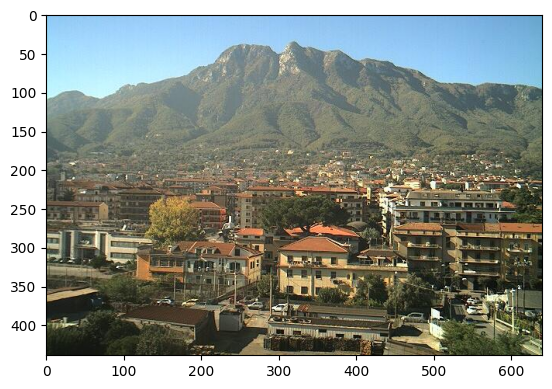

In [45]:
random_img_viz(train_img)

### Langkah 3 - Pra Pengolahan Data

In [46]:
	def standarized_input(image):
	    # resize to w: 1100, h:600
	    std_img = cv2.resize(image, (1100,600))

	    return std_img

Selanjutnya, buatlah fungsi untuk kebutuhan encoding label.




In [47]:
	def label_encoder(label):
	    # Encode the label
	    # day as 1; night as 0
	    num_val = 0

	    if(label == 'day'):
	        num_val = 1

	    return num_val

Terakhir, buatlah fungsi untuk melakukan kedua hal tersebut secara sekaligus untuk semua gambar dalam list.




In [48]:
	def preprocess(img_list):
	    std_img_list = []

	    for item in img_list:
	        image = item[0]
	        label = item[1]

	        # Standarized the image
	        std_img = standarized_input(image)

	        # Create the label
	        img_label = label_encoder(label)

	        std_img_list.append((std_img, img_label))

	    return std_img_list

Lakukan pra pengolahan data pada data training.

In [49]:
train_std_img_list = preprocess(train_img)

Lakukan pengecekan ukuran gambar secara acak.




In [50]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_std_img_list))

	# Check img size
	print(f'Image {pick_random}')
	print(train_std_img_list[pick_random][0].shape)

Image 223
(600, 1100, 3)


### Langkah 4 - Ekstraksi Fitur


Buatlah fungsi berikut untuk mendapatkan nilai rata-rata tingkat kecerahan.




In [51]:
	# Get feature based on average brightness using HSV colorspace
	def avg_brightness(image):
	    # Convert image to HSV
	    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

	    # Calculate the avg of brightness
	    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
	    area = image.shape[0] * image.shape[1]
	    avg = sum_brightness / area

	    return avg

Lakukan pengecekan pada gambar secara acak. INGAT! Gunakan gambar yang telah melalui proses pra pengolahan data!




Image 105
Avg Brighness: 158.0110


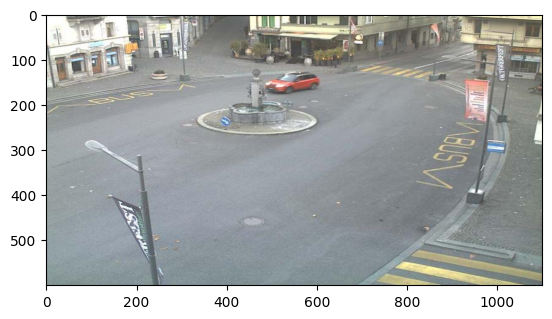

In [52]:
	# Check on random image
	rand_img = np.random.randint(0, len(train_std_img_list))

	feature_img = train_std_img_list[rand_img][0]

	avg_img = avg_brightness(feature_img)

	print(f'Image {rand_img}')
	print(f'Avg Brighness: {avg_img:.4f}')
	plt.imshow(feature_img)

### Langkah 5 - Klasifikasi dengan Metode Threshold


In [53]:
	def predict_label(img, threshold):
	    # Computer average brightness
	    avg = avg_brightness(img)
	    pred = 0

	    # Predict the label based on user defined threshold
	    if avg > threshold:
	        pred = 1

	    return pred

Lakukan pengecekan prediksi secara acak pada data training




Image 181
Actual label: 0
Predicted label: 0


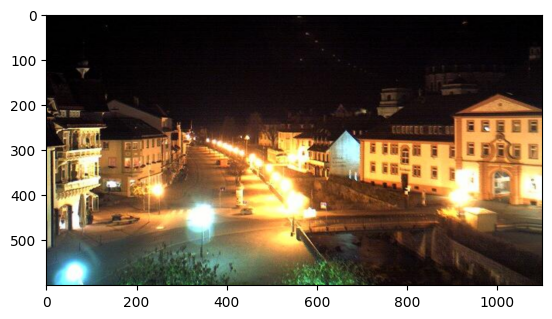

In [54]:
	# Test the classifier on train data
	rand_img = np.random.randint(0, len(train_std_img_list))

	pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

	# Evaluate
	print(f'Image {rand_img}')
	print(f'Actual label: {train_std_img_list[rand_img][1]}')
	print(f'Predicted label: {pred}')
	plt.imshow(train_std_img_list[rand_img][0])

### Langkah 6 - Evaluasi Manual

In [55]:
	def evaluate(img_list, threshold):
	    miss_labels = []

	    for file in img_list:
	        # Get the ground truth / correct label
	        img = file[0]
	        label = file[1]

	        # Get prediction
	        pred_label = predict_label(img, threshold)

	        # Compare ground truth and pred
	        if pred_label != label:
	            miss_labels.append((img, pred_label, label))

	    total_img = len(img_list)
	    corr_pred = total_img - len(miss_labels)
	    accuracy = corr_pred / total_img

	    print(f'Accuracy: {accuracy:.4f}')

Lakukan evaluasi pada data training dengan nilai ambang batas 120.




In [56]:
	# Evaluate on train data
	evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


Selanjutnya, kita akan melakukan evaluasi pada data testing. Namun sebelumnya, data testing harus diperlakukan sama dengan data training dalam konteks pra progolahan data dan ekstraksi fitur.




In [57]:
	# Evaluate on test data

	# Load test data
	test_img = load_dataset(test_dir)

	# Preprocess
	test_std_img_list = preprocess(test_img)

	# Predict
	evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


# Klasifikasi dengan SVM


### Langkah 4 Alternatif - Membuat Feature Vectors.


In [58]:
	# Create function to extract feature for every images and stored in tabular data
	# Stored in Pandas dataframe
	def extract_avg_bright_feature(img_list):
	    avg_list = []
	    labels = []

	    for img in img_list:
	        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
	        img_label = img[1] # Get the image label

	        avg_list.append(img_avg)
	        labels.append(img_label)

	    # Stack data in columcular way
	    data = np.column_stack((avg_list, labels))
	    # Create a Pandas dataframe
	    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

	    return df

Cek hasilnya pada data training,




In [59]:
	# Extract feature on train data
	train_avg_img = extract_avg_bright_feature(train_std_img_list)
	print(f'Shape: {train_avg_img.shape}')
	train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,143.364305,1.0
1,110.086635,1.0
2,157.366744,1.0
3,107.650714,1.0
4,143.662879,1.0


Lakukan langkah yang serupa pada data testing




In [60]:
	# Do the same thing on test data
	test_avg_img = extract_avg_bright_feature(test_std_img_list)
	print(f'Shape: {test_avg_img.shape}')
	test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,150.341579,1.0
1,129.381088,1.0
2,153.885708,1.0
3,93.140527,1.0
4,157.186358,1.0


### Langkah 5 - Buat Model SVM


In [61]:
	# import requied library
	from sklearn.svm import SVC

	# Split data and label
	X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
	y_train = train_avg_img.iloc[:,1]
	X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
	y_test = test_avg_img.iloc[:,1]

	model = SVC()
	model.fit(X_train, y_train)

SVC()

### Langkah 6 - Evaluasi


In [62]:
	from sklearn.metrics import accuracy_score

	# Make a prediction on train data
	y_train_pred = model.predict(X_train)

	# Get the accuracy on train data
	acc_train = accuracy_score(y_train, y_train_pred)

	# Make a prediction on test data
	y_test_pred = model.predict(X_test)

	# Get the accuracy on test data
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print Eval Result
	print(f'Accuracy on train: {acc_train}')
	print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


# Tugas Praktikum


In [2]:
from google.colab import files
uploaded = files.upload()

Saving voice.csv to voice.csv


### Soal 1: Buatlah model SVM dengan menggunakan data voice.csv


(3168, 21)
label
male      1584
female    1584
Name: count, dtype: int64
Rasio Split Kernel  Akurasi Train  Akurasi Test
      70:30 linear         0.9720        0.9790
      70:30   poly         0.9666        0.9600
      70:30    rbf         0.9838        0.9832
      80:20 linear         0.9767        0.9748
      80:20   poly         0.9680        0.9558
      80:20    rbf         0.9838        0.9826

Tabel Akurasi Data Test:
Rasio Split   70:30   80:20
Kernel                     
linear       0.9790  0.9748
poly         0.9600  0.9558
rbf          0.9832  0.9826


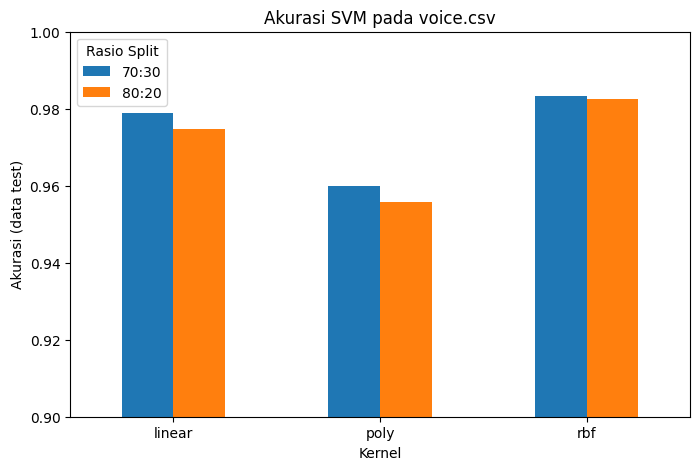

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# ===== Load data =====
df = pd.read_csv('voice.csv')
print(df.shape)
print(df['label'].value_counts())

X = df.drop('label', axis=1)
y = df['label']          # 'male' / 'female'

# ===== Eksperimen: 2 rasio split x 3 kernel =====
splits = {'70:30': 0.30, '80:20': 0.20}
kernels = ['linear', 'poly', 'rbf']

hasil = []
for nama_split, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y)

    for kernel in kernels:
        # Scaling wajib untuk SVM; dimasukkan ke pipeline agar tidak data leakage
        model = make_pipeline(StandardScaler(), SVC(kernel=kernel, random_state=42))
        model.fit(X_train, y_train)

        acc_train = accuracy_score(y_train, model.predict(X_train))
        acc_test = accuracy_score(y_test, model.predict(X_test))

        hasil.append({
            'Rasio Split': nama_split,
            'Kernel': kernel,
            'Akurasi Train': round(acc_train, 4),
            'Akurasi Test': round(acc_test, 4),
        })

hasil_df = pd.DataFrame(hasil)
print(hasil_df.to_string(index=False))

# ===== Tabulasi akurasi data test (baris = kernel, kolom = split) =====
tabel = hasil_df.pivot(index='Kernel', columns='Rasio Split', values='Akurasi Test')
tabel = tabel.loc[kernels]
print("\nTabel Akurasi Data Test:")
print(tabel)

# ===== Visualisasi =====
tabel.plot(kind='bar', figsize=(8, 5), ylim=(0.9, 1.0))
plt.title('Akurasi SVM pada voice.csv')
plt.ylabel('Akurasi (data test)')
plt.xticks(rotation=0)
plt.legend(title='Rasio Split')
plt.show()

### soal 2: Gunakan data pada praktikum 5 untuk membuat model klasifikasi siang dan malam menggunakan SVM dengan kernel RBF menggunakan fitur histrogram.

day: 200 gambar ditemukan
night: 200 gambar ditemukan
Dimensi fitur: (400, 96)
Akurasi baseline (C=1, gamma=scale): 0.9875
Parameter terbaik: {'svc__C': 1, 'svc__gamma': 0.001}
Akurasi CV terbaik: 0.9875
Akurasi test setelah tuning: 0.9875
[[40  0]
 [ 1 39]]
              precision    recall  f1-score   support

         day       0.98      1.00      0.99        40
       night       1.00      0.97      0.99        40

    accuracy                           0.99        80
   macro avg       0.99      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



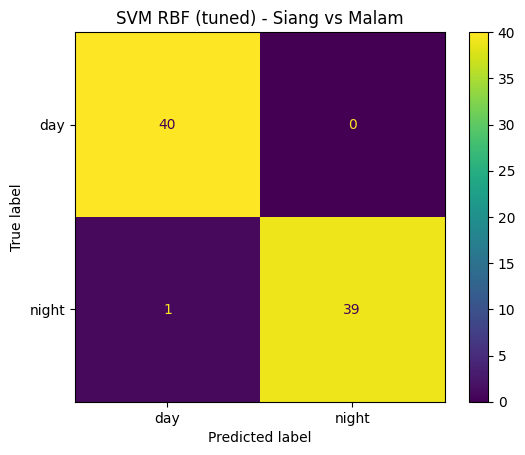

    C  gamma  Akurasi CV
100.0  0.001    0.987500
  1.0  0.001    0.987500
 10.0  0.001    0.984375
 10.0  scale    0.984375
100.0  scale    0.984375
100.0   0.01    0.984375
 10.0   0.01    0.984375
  1.0  scale    0.981250
  1.0   0.01    0.981250
100.0    0.1    0.978125


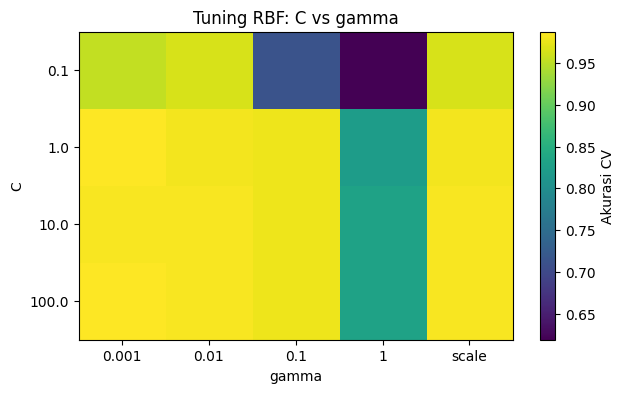

      Model  Akurasi Test
RBF default        0.9875
  RBF tuned        0.9875


In [16]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

# ===== Konfigurasi =====
KELAS = {'day': 0, 'night': 1}
BINS = 32
UKURAN = (128, 128)                  # resize agar seragam

# ===== Ekstraksi fitur histogram RGB =====
def ekstrak_histogram(path):
    img = Image.open(path).convert('RGB').resize(UKURAN)
    arr = np.array(img)
    fitur = []
    for c in range(3):                                   # R, G, B
        hist, _ = np.histogram(arr[:, :, c], bins=BINS, range=(0, 256))
        fitur.extend(hist / hist.sum())                  # normalisasi
    return fitur

# Cari lokasi folder training dan test secara rekursif di current directory
train_paths = []
test_paths = []

for root, dirs, files in os.walk('.'):
    if 'training' in root.split(os.sep):
        train_paths.append(root)
    if 'test' in root.split(os.sep):
        test_paths.append(root)

X, y = [], []
for nama, label in KELAS.items():
    files = []
    # Kumpulkan semua file dari folder yang sesuai nama kelas
    for p in list(set(train_paths + test_paths)):
        if p.endswith(nama):
            for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG'):
                files += glob.glob(os.path.join(p, ext))

    files = list(set(files))
    print(f'{nama}: {len(files)} gambar ditemukan')
    for f in files:
        try:
            X.append(ekstrak_histogram(f))
            y.append(label)
        except Exception as e:
            print(f'Gagal membaca {f}: {e}')

X = np.array(X)
y = np.array(y)

if len(X) == 0:
    raise ValueError("Dataset gambar kosong! Pastikan file images.zip telah diekstrak dengan benar menggunakan zipfile di langkah sebelumnya.")

print('Dimensi fitur:', X.shape)

# ===== Split 80:20 =====
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# ===== Baseline: SVM RBF default =====
base = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
base.fit(X_train, y_train)
acc_base = accuracy_score(y_test, base.predict(X_test))
print(f'Akurasi baseline (C=1, gamma=scale): {acc_base:.4f}')

# ===== Hyperparameter tuning RBF (hanya pada data latih, 5-fold CV) =====
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1],
}
pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

print('Parameter terbaik:', grid.best_params_)
print(f'Akurasi CV terbaik: {grid.best_score_:.4f}')

# ===== Evaluasi model terbaik pada data test =====
best = grid.best_estimator_
y_pred = best.predict(X_test)
acc_tuned = accuracy_score(y_test, y_pred)
print(f'Akurasi test setelah tuning: {acc_tuned:.4f}')
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=list(KELAS.keys())))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=list(KELAS.keys()))
plt.title('SVM RBF (tuned) - Siang vs Malam')
plt.show()

# ===== Catat hasil semua kombinasi (C x gamma) =====
hasil = pd.DataFrame(grid.cv_results_)[['param_svc__C', 'param_svc__gamma', 'mean_test_score']]
hasil.columns = ['C', 'gamma', 'Akurasi CV']
print(hasil.sort_values('Akurasi CV', ascending=False).head(10).to_string(index=False))

# Heatmap C vs gamma
pivot = hasil.assign(gamma=hasil['gamma'].astype(str)).pivot(index='C', columns='gamma', values='Akurasi CV')
plt.figure(figsize=(7, 4))
plt.imshow(pivot.values, cmap='viridis', aspect='auto')
plt.colorbar(label='Akurasi CV')
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel('gamma')
plt.ylabel('C')
plt.title('Tuning RBF: C vs gamma')
plt.show()

# ===== Ringkasan untuk laporan =====
print(pd.DataFrame({
    'Model': ['RBF default', 'RBF tuned'],
    'Akurasi Test': [round(acc_base, 4), round(acc_tuned, 4)],
}).to_string(index=False))